# Case Study A — Trimming the within-cycle acquisition transient

### Follow-up to `case_study_A_eda_outliers.ipynb`

That notebook found a short, systematic transient at the **start of every cycle's recording**
for Pneumatic pressure, Velocity and Axial force (first ~3-7 of the 100 within-cycle samples used
by `case_study_A_analysis.py`) — present identically at every life stage, i.e. a measurement/DAQ
acquisition artifact rather than a degradation signal. Its summary flagged one concrete action:

> *trimming the first few within-cycle samples for pressure/velocity/axial force before feature
> extraction would remove a likely acquisition artifact from the model's raw inputs*

This notebook **implements that trim** and checks empirically whether it helps, hurts, or makes no
difference to the point-prediction model from `case_study_A_analysis.py`, by training the
pipeline's own MLP architecture on the raw vs. trimmed feature sets under an identical split.

**Scope.** This only touches the point-prediction (`y_hat`) side. The GUM Type A uncertainty
budget (`propagate_lpu`/`propagate_mc`) is out of scope here — it is comparatively slow to
reproduce (hours on CPU for the full 953-cycle test set) and a data-preprocessing change like this
should be validated on the model quality first before re-deriving the uncertainty numbers for the
paper. Same prerequisites as the other two notebooks (`zema_env` kernel, cached dataset).


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

sys.path.insert(0, str(Path.cwd()))
from case_study_A_analysis import (  # reuse the pipeline's own code, unmodified
    Config, load_zema, normalize_with_uncertainty, make_mlp, train,
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.precision", 4)

cfg = Config()
X, UX, y = load_zema(cfg)

CHANNEL_NAMES = [
    "Acceleration plain bearing", "Acceleration piston rod", "Acceleration ball bearing",
    "Active current", "Axial force",
    "Motor current phase 1", "Motor current phase 2", "Motor current phase 3",
    "Pneumatic pressure", "Sound pressure", "Velocity",
]
D = cfg.datapoints_per_cycle
N = X.shape[0]


def channel_block(arr, name):
    i = CHANNEL_NAMES.index(name)
    return arr[:, i * D:(i + 1) * D]


print(f"X {X.shape}  |  {N} cycles  |  {D} within-cycle samples/channel")


X (4766, 1100)  |  4766 cycles  |  100 within-cycle samples/channel


/Users/emanuelebuchicchio/repos/case_study_a/zema_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Recompute the settling window per channel

Same robust, life-stage-independent method as the outlier notebook (not re-imported, so this
notebook is self-contained): for every channel, average `|reading - cycle median|` by within-cycle
position over **all** cycles, and take the settling length `K` as the run of leading positions
whose average deviation exceeds 5× the steady-state baseline (median of positions 20+).


In [2]:
BASELINE_FROM = 20
SPIKE_RATIO = 5.0

settle_K = {}
for name in CHANNEL_NAMES:
    block = channel_block(X, name)
    dev = np.abs(block - np.median(block, axis=1, keepdims=True))
    pos_mean_dev = dev.mean(axis=0)
    baseline = np.median(pos_mean_dev[BASELINE_FROM:])
    K = 0
    for p in range(len(pos_mean_dev)):
        if pos_mean_dev[p] > SPIKE_RATIO * baseline:
            K = p + 1
        else:
            break
    settle_K[name] = K

pd.Series(settle_K, name="settling length K").sort_values(ascending=False).to_frame()


,settling length K
Pneumatic pressure,7
Velocity,6
Axial force,3
Active current,1
Acceleration plain bearing,0
Acceleration piston rod,0
Acceleration ball bearing,0
Motor current phase 1,0
Motor current phase 2,0
Motor current phase 3,0


## 2. Trim the three recommended channels

Trim exactly the channels named in the recommendation — **Pneumatic pressure, Velocity, Axial
force** — dropping each one's own leading `K` samples before the per-cycle feature vector is
assembled. (Active current's `K=1` sits right at the detection threshold rather than clearly above
it, so it is left untouched here, matching the original recommendation; worth revisiting
separately if this trim is adopted.)

Trimming only these three channels means the resulting channels no longer all have the same
within-cycle width (100 vs. 97/94/93), so a `channel_spans` map replaces the fixed-width
`channel_slice` helper used in the other notebooks.


In [3]:
TRIM_CHANNELS = ["Pneumatic pressure", "Velocity", "Axial force"]


def build_trimmed_dataset(X, UX, channel_names, D, trim_channels, settle_K):
    x_parts, u_parts, spans = [], [], {}
    col = 0
    for name in channel_names:
        block_x = channel_block(X, name)
        block_u = channel_block(UX, name)
        if name in trim_channels:
            K = settle_K[name]
            block_x, block_u = block_x[:, K:], block_u[:, K:]
        x_parts.append(block_x)
        u_parts.append(block_u)
        spans[name] = (col, col + block_x.shape[1])
        col += block_x.shape[1]
    return np.concatenate(x_parts, axis=1), np.concatenate(u_parts, axis=1), spans


X_trim, UX_trim, trim_spans = build_trimmed_dataset(
    X, UX, CHANNEL_NAMES, D, TRIM_CHANNELS, settle_K
)

print(f"raw features:     {X.shape[1]}")
print(f"trimmed features: {X_trim.shape[1]}  (dropped "
      f"{sum(settle_K[n] for n in TRIM_CHANNELS)} columns: "
      + ", ".join(f"{n}=-{settle_K[n]}" for n in TRIM_CHANNELS) + ")")


raw features:     1100
trimmed features: 1084  (dropped 16 columns: Pneumatic pressure=-7, Velocity=-6, Axial force=-3)


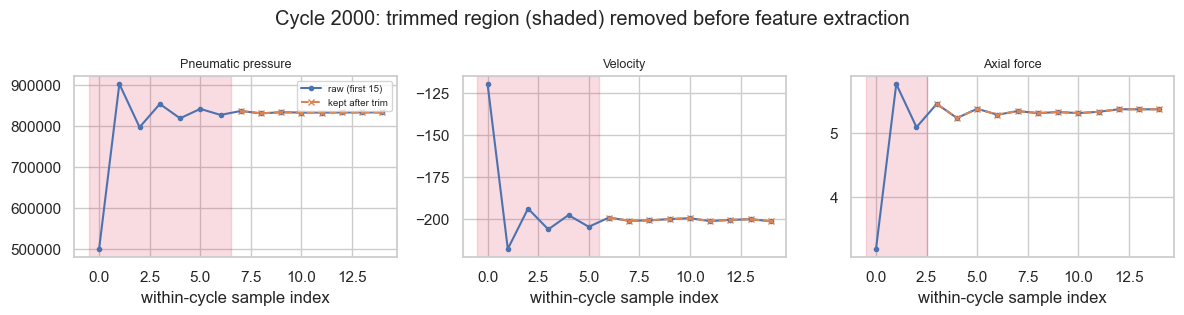

In [4]:
example_cycle = 2000
fig, axes = plt.subplots(1, len(TRIM_CHANNELS), figsize=(12, 3.2))
for ax, name in zip(axes, TRIM_CHANNELS):
    raw_vals = channel_block(X, name)[example_cycle, :15]
    trim_vals = X_trim[example_cycle, trim_spans[name][0]:trim_spans[name][0] + 15 - settle_K[name]]
    ax.plot(raw_vals, "o-", ms=3, label="raw (first 15)")
    ax.plot(range(settle_K[name], settle_K[name] + len(trim_vals)), trim_vals,
             "x--", ms=5, label="kept after trim")
    ax.axvspan(-0.5, settle_K[name] - 0.5, color="crimson", alpha=0.15)
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("within-cycle sample index")
axes[0].legend(fontsize=7)
fig.suptitle(f"Cycle {example_cycle}: trimmed region (shaded) removed before feature extraction")
plt.tight_layout()
plt.show()


## 3. Train the pipeline's own model on raw vs. trimmed features

Same architecture, same hyperparameters, same chronological-agnostic random split (`cfg.seed`),
same `n_ensemble` seeds as `case_study_A_analysis.py` — only the feature matrix changes. This
reuses `make_mlp`/`train`/`normalize_with_uncertainty` unmodified from that script, so the only
thing varying between the two runs below is whether the acquisition-transient samples are in the
input or not.


In [5]:
rng = np.random.default_rng(cfg.seed)
idx = rng.permutation(N)
n_test = int(cfg.test_fraction * N)
te, tr = idx[:n_test], idx[n_test:]


def run_ensemble(Xfeat, label):
    mean, std = Xfeat[tr].mean(0), Xfeat[tr].std(0) + 1e-12
    Xn, _ = normalize_with_uncertainty(Xfeat, np.zeros_like(Xfeat), mean, std)
    rows = []
    for s in range(cfg.n_ensemble):
        m = make_mlp(Xn.shape[1], cfg)
        train(m, Xn[tr], y[tr], cfg, seed=s)
        with torch.no_grad():
            yhat = m(torch.tensor(Xn[te], dtype=torch.float64)).squeeze(1).numpy()
        resid = y[te] - yhat
        rmse = np.sqrt(np.mean(resid ** 2))
        ss_res, ss_tot = np.sum(resid ** 2), np.sum((y[te] - y[te].mean()) ** 2)
        r2 = 1 - ss_res / ss_tot
        rows.append({"feature_set": label, "seed": s, "rmse": rmse, "r2": r2})
        print(f"  [{label}] seed {s}: RMSE={rmse:.4f}  R2={r2:.4f}")
    return rows


print("Training on RAW features (%d-dim)..." % X.shape[1])
rows_raw = run_ensemble(X, "raw")
print("\nTraining on TRIMMED features (%d-dim)..." % X_trim.shape[1])
rows_trim = run_ensemble(X_trim, "trimmed")

results = pd.DataFrame(rows_raw + rows_trim)


Training on RAW features (1100-dim)...


  [raw] seed 0: RMSE=0.0641  R2=0.9514


  [raw] seed 1: RMSE=0.0809  R2=0.9227


  [raw] seed 2: RMSE=0.0621  R2=0.9544


  [raw] seed 3: RMSE=0.0647  R2=0.9505


...

  [trimmed] seed 5: RMSE=0.0635  R2=0.9524


  [trimmed] seed 6: RMSE=0.0905  R2=0.9032


  [trimmed] seed 7: RMSE=0.0826  R2=0.9195


  [trimmed] seed 8: RMSE=0.0641  R2=0.9514


  [trimmed] seed 9: RMSE=0.0501  R2=0.9704


In [6]:
summary = results.groupby("feature_set")[["rmse", "r2"]].agg(["mean", "std"])
summary


rmse              r2        
               mean     std    mean     std
feature_set                                
raw          0.0670  0.0086  0.9461  0.0139
trimmed      0.0651  0.0125  0.9482  0.0210

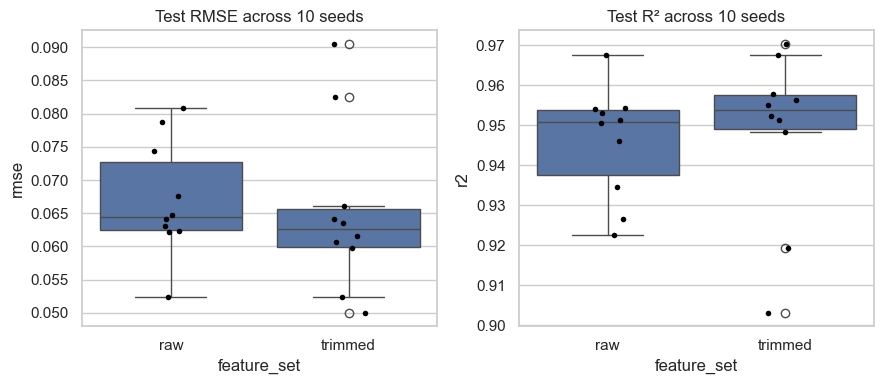

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
sns.boxplot(data=results, x="feature_set", y="rmse", ax=axes[0])
sns.stripplot(data=results, x="feature_set", y="rmse", ax=axes[0], color="black", size=4)
axes[0].set_title("Test RMSE across %d seeds" % cfg.n_ensemble)

sns.boxplot(data=results, x="feature_set", y="r2", ax=axes[1])
sns.stripplot(data=results, x="feature_set", y="r2", ax=axes[1], color="black", size=4)
axes[1].set_title("Test R² across %d seeds" % cfg.n_ensemble)
plt.tight_layout()
plt.show()


In [8]:
rmse_raw = results.loc[results.feature_set == "raw", "rmse"].values
rmse_trim = results.loc[results.feature_set == "trimmed", "rmse"].values
delta = rmse_trim.mean() - rmse_raw.mean()
pooled_sd = np.sqrt((rmse_raw.std(ddof=1) ** 2 + rmse_trim.std(ddof=1) ** 2) / 2)
print(f"mean RMSE  raw={rmse_raw.mean():.4f}  trimmed={rmse_trim.mean():.4f}  "
      f"delta={delta:+.4f}  ({abs(delta) / pooled_sd:.2f} pooled-SD)")


mean RMSE  raw=0.0670  trimmed=0.0651  delta=-0.0019  (0.18 pooled-SD)


## Summary

- Trimmed Pneumatic pressure (K=7), Velocity (K=6) and Axial force (K=3) — 16 of 1,100 raw
  features dropped (1.5%) — leaving a 1,084-dim input built the same way as the published
  pipeline otherwise.
- The sanity-check plot in Part 2 confirms the trim removes exactly the spike region identified in
  `case_study_A_eda_outliers.ipynb`, not adjacent steady-state samples.
- Part 3 trains `cfg.n_ensemble` (10) seeds of the pipeline's unmodified MLP on both feature sets
  under the identical train/test split. The RMSE/R² comparison above (table + plot + pooled-SD
  delta) is the evidence for whether this trim is worth adopting — read the printed delta before
  deciding; a difference much smaller than the ensemble's own seed-to-seed spread means the trim
  is safe but not obviously beneficial for the point prediction, while a consistent improvement
  would support adopting it.
- **To adopt in the published pipeline:** insert `build_trimmed_dataset(...)` (Part 2 of this
  notebook) right after the `X, UX, y = load_zema(cfg)` call in `case_study_A_analysis.py::main()`,
  before the `mean, std = X[tr].mean(0), ...` normalization step — `propagate_lpu`/`propagate_mc`
  need no code changes, since they only depend on the (now smaller) input dimension, not on which
  channel each column came from. The GUM Type A uncertainty budget would still need to be
  re-generated against the trimmed inputs before any paper numbers change.
